In [40]:
%load_ext autoreload
%autoreload 2

from src.DicomRTHandler import DicomRTHandler
from src.config_presets.tools.load_config import load_config
import numpy as np
import os
from src.preprocessing.main import preprocess_numpy_data
from tqdm import tqdm

config = load_config('HNC/UMCG_data.yaml')


ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\CT"
rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTDOSE\IM1.DCM"
rtstruct_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT\RS1.2.752.243.1.1.20220324125917617.1240.35401.dcm"
CITOR_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT"
DLC_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\DLC\9296488\no_contrast\RTSTRUCT"  # can also be None if no DLCs are needed
DLC_RTSTRUCT_DIR = None

output_dir = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\Users\Daniel MacRae\stride_RT\TEST_OUTPUT"

# enable and disable verbose print statements (mostly used for debugging)
VERBOSE = False

handler = DicomRTHandler(config, verbose=VERBOSE)



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
src\config_presets\HNC/UMCG_data.yaml


In [34]:

HNC_base_dir = r"\\zkh\appdata\RTResearchArchief\HOOFDHALS_BASE\Data"
destination_dir = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\Users\Daniel MacRae\Z. Other stuff\PRIMA_data_checks\HNC_Base_checks"
patient_ids_list = os.listdir(HNC_base_dir)
patient_ids_list.sort()
len(patient_ids_list)

1677

In [35]:
list_one = ['4628069', '5768025', '7822891', '3608845', '1097433', '0020715', '5896858', '2087361', '2083033', '9577277', '3274619', '0345451', '1872399', '2259310', '2376970', '9016977', '4821215', '4054457']
list_two = ['1178564', '9445856']
list_three = ['2076094', '2080453', '5262401', '7985090', '2120032', '3979255', '2199947', '9692367', '2002365', '0454580', '2358949', '7693337', '2365752', '2393545', '2394651', '8303802', '9115342', '0643911']


total_list = list_one + list_two + list_three
total_list = list(set(total_list))  # remove duplicates


In [11]:
'0020715' in patient_ids_list

True

In [31]:
patient_subdirs

['20210915']

In [ ]:
temp_list = ['7822891']

config = load_config('HNC/UMCG_data_only_oral_cavity.yaml')

for patient_id in tqdm(total_list[:2]):
    patient_source_dir = os.path.join(HNC_base_dir, patient_id)
    patient_subdirs = os.listdir(patient_source_dir)
    patient_subdirs.sort()

    destination_dir_patient = os.path.join(destination_dir, patient_id)
    os.makedirs(destination_dir_patient, exist_ok=True)

    
    
    if len(patient_subdirs) != 1:
        print(f"Patient ID: {patient_id}, Subdirectories: {patient_subdirs}")

    for subdir in patient_subdirs:
        patient_folder_dir = os.path.join(patient_source_dir, subdir)

        ct_folder_dir = os.path.join(patient_folder_dir, "CT")
        rtdose_folder_path = os.path.join(patient_folder_dir, "RTDOSE")

        if len(os.listdir(rtdose_folder_path)) != 1:
            print(f"Patient ID: {patient_id}, Subdirectory: {subdir}, RTDOSE files: {os.listdir(rtdose_folder_path)}")
            #continue  # Skip this patient if there are multiple RTDOSE files

        for idx, rtdose_file in enumerate(os.listdir(rtdose_folder_path)):

            handler = DicomRTHandler(config, verbose=False)
            
            rtdose_file_path = os.path.join(rtdose_folder_path, rtdose_file)
            RTSTRUCT_dir = os.path.join(patient_folder_dir, "RTSTRUCT")

            # # Load data 

            # # load the CT files
            handler.load_ct_series(ct_folder_dir)
            #handler.load_rtdose(rtdose_file_path)
            handler.load_rtstructs(RTSTRUCT_dir, DLC_folder_dir = None, fix_uids=True)


            # preprocessed_CT, preprocessed_RTSTRUCT, preprocessed_RTDOSE = preprocess_numpy_data(config, handler)

            # dest_subdir_patient = os.path.join(destination_dir, patient_id, subdir)
            # os.makedirs(dest_subdir_patient, exist_ok=True)

            # np.save(os.path.join(dest_subdir_patient, f"CT_{idx}.npy"), preprocessed_CT)
            # np.save(os.path.join(dest_subdir_patient, f"RTSTRUCT_{idx}.npy"), preprocessed_RTSTRUCT)
            # np.save(os.path.join(dest_subdir_patient, f"RTDOSE_{idx}.npy"), preprocessed_RTDOSE)


            # del handler, preprocessed_CT, preprocessed_RTSTRUCT, preprocessed_RTDOSE

    

src\config_presets\HNC/UMCG_data_only_oral_cavity.yaml


  0%|          | 0/2 [00:00<?, ?it/s]

Patient ID: 9577277, Subdirectories: ['20190212', '20210601']


 50%|█████     | 1/2 [00:21<00:21, 21.98s/it]

Patient ID: 2259310, Subdirectory: 20210630, RTDOSE files: ['RTDOSE_1.2.752.243.1.1.20210715100908421.7000.56285.1_1_1_1775697764013e.dcm', 'RTDOSE_1.2.752.243.1.1.20210714094045960.3100.31646.1_1_1_17652875042ea3.dcm']


100%|██████████| 2/2 [00:59<00:00, 29.58s/it]


In [47]:
x_counts

Counter({'1': 771, '4': 652, '3': 533, '2': 530, '5': 529, '6': 521, '7': 474})

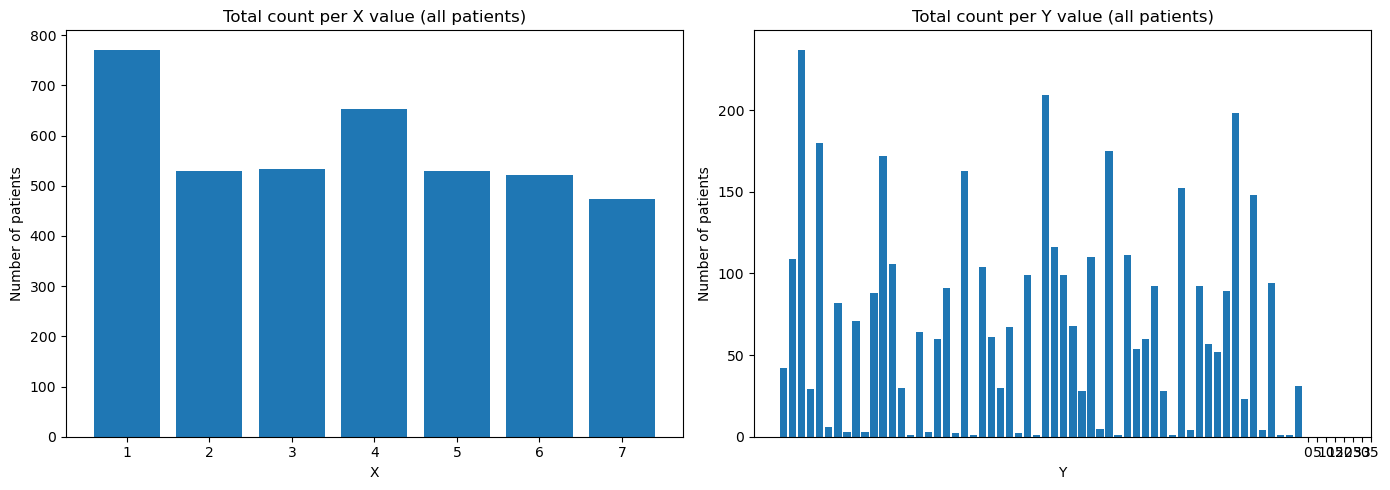

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(sorted(x_counts, key=lambda value: int(value)), 
            [x_counts[x] for x in sorted(x_counts, key=lambda value: int(value))])
axes[0].set_title("Total count per X value (all patients)")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Number of patients")

axes[1].bar(sorted(y_counts, key=lambda value: float(value)), 
            [y_counts[y] for y in sorted(y_counts, key=lambda value: float(value))])
axes[1].set_title("Total count per Y value (all patients)")
axes[1].set_xlabel("Y")
axes[1].set_ylabel("Number of patients")
axes[1].set_xticks([str(v) for v in range(0, int(max(float(y) for y in y_counts)) + 1, 5)])

plt.tight_layout()
plt.show()

In [22]:
# prints some (very basic) metadata about the loaded data
handler.print_summary()


DICOM RT DATA SUMMARY

CT Series:
  PatientID: 7822891
  ScanDate: 20210528
  Manufacturer: SIEMENS
  ModelName: SOMATOM Definition AS
  KiloVoltPeak: 120.0
  ImageOrientationPatient: [1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0, 0, 1]
  ImagePositionPatient: [-249.51171875, -453.51171875, -260.0]
  Spacing: [0.9765625, 0.9765625]
  RescaleSlope: 1.0
  RescaleIntercept: -1024.0
  SliceThickness: 2.0

RT Dose:
  Matrix: (512, 512, 216)
  Spacing (z,y,x): (0.9765625, 0.9765625, 2.0) mm
  Origin: (-249.51171875, -453.51171875, -260.0) mm


In [13]:
mean_OAR_doses_dict = handler.compute_structure_DVHs(dose_units='Gy')


Structure mean doses and volumes:
  Submandibular_R_Out: mean dose = 31.08 Gy, volume = 3.75 cm3
  buccalmucosa_re: mean dose = 31.90 Gy, volume = 10.89 cm3
  parotis_li: mean dose = 37.30 Gy, volume = 58.61 cm3
  mandible: mean dose = 30.63 Gy, volume = 73.56 cm3
  Thyroid_Out: mean dose = 36.13 Gy, volume = 5.12 cm3
  glotticarea: mean dose = 19.76 Gy, volume = 8.12 cm3
  Parotid_R_Out: mean dose = 28.99 Gy, volume = 47.42 cm3
  PCM_Sup_Out: mean dose = 44.02 Gy, volume = 0.40 cm3
  PCM_Inf_Out: mean dose = 21.80 Gy, volume = 3.97 cm3
  parotis_re: mean dose = 35.39 Gy, volume = 61.00 cm3
  pcm_inf: mean dose = 32.34 Gy, volume = 6.80 cm3
  pcm_sup: mean dose = 60.62 Gy, volume = 9.75 cm3
  buccalmucosa_li: mean dose = 34.26 Gy, volume = 9.13 cm3
  submandibularis_li: mean dose = 52.63 Gy, volume = 13.26 cm3
  Submandibular_L_Out: mean dose = 31.37 Gy, volume = 2.83 cm3
  Esophagus_Cerv_Out: mean dose = 11.77 Gy, volume = 3.02 cm3
  pcm_med: mean dose = 46.73 Gy, volume = 8.21 cm3
 

# Prepare dataset for DL models:

In [23]:
import SimpleITK as sitk

from src.preprocessing.main import preprocess_numpy_data

preprocessed_CT, preprocessed_RTSTRUCT, preprocessed_RTDOSE = preprocess_numpy_data(config, handler)


  - Segmentation shape: (216, 512, 512)
  - Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
  - Background voxels: 56481202
  - Structure voxels: 141902
 -- applying spacing correction --
   Original spacing: (0.9765625, 0.9765625, 2.0)
Resampling image from spacing (0.9765625, 0.9765625, 2.0) to [1, 1, 2]
Resampling image from spacing (0.9765625, 0.9765625, 2.0) to [1, 1, 2]
Resampling image from spacing (0.9765625, 0.9765625, 2.0) to [1, 1, 2]
   Corrected spacing: (1.0, 1.0, 2.0)
OARs in z direction: ['parotis_li', 'parotis_re', 'crico', 'thyroid', 'mandible']
OAR values in z direction: [1, 2, 5, 6, 7]
upper_coord: 155, lower_coord: 72
OARs in x direction: ['parotis_li', 'parotis_re']
OAR values in x direction: [1, 2]
upper_coord: 212, lower_coord: 163
OARs in y direction: ['parotis_li', 'parotis_re', 'submandibularis_li', 'submandibularis_re']
OAR values in y direction: [1, 2, 3, 4]
upper_coord: 325, lower_coord: 182


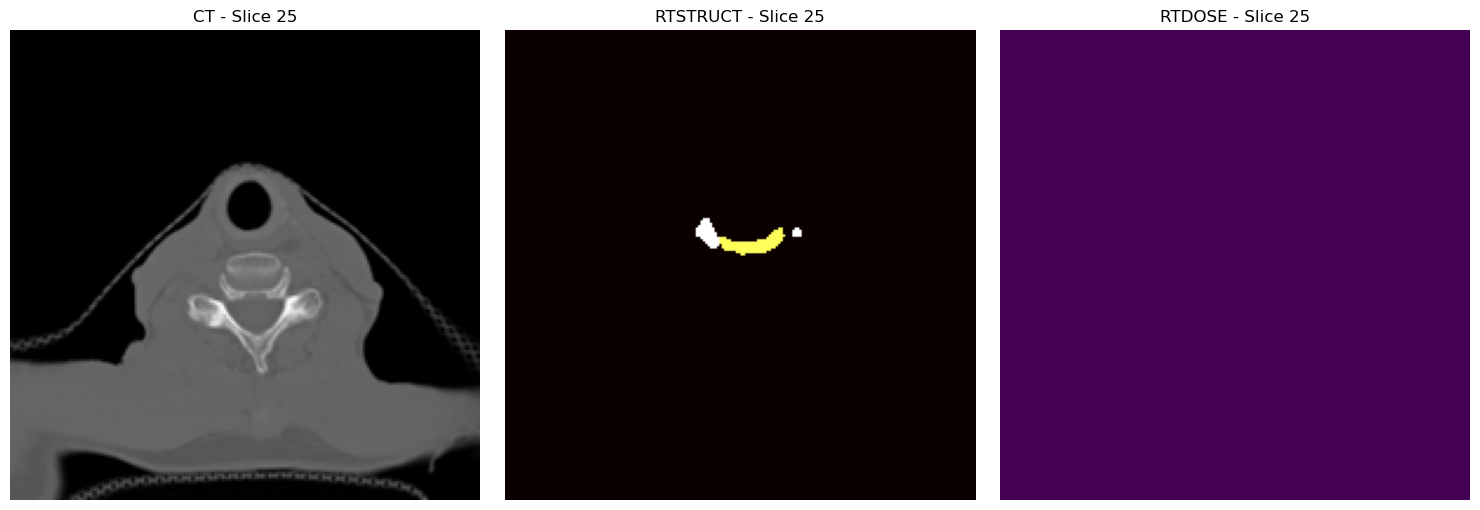

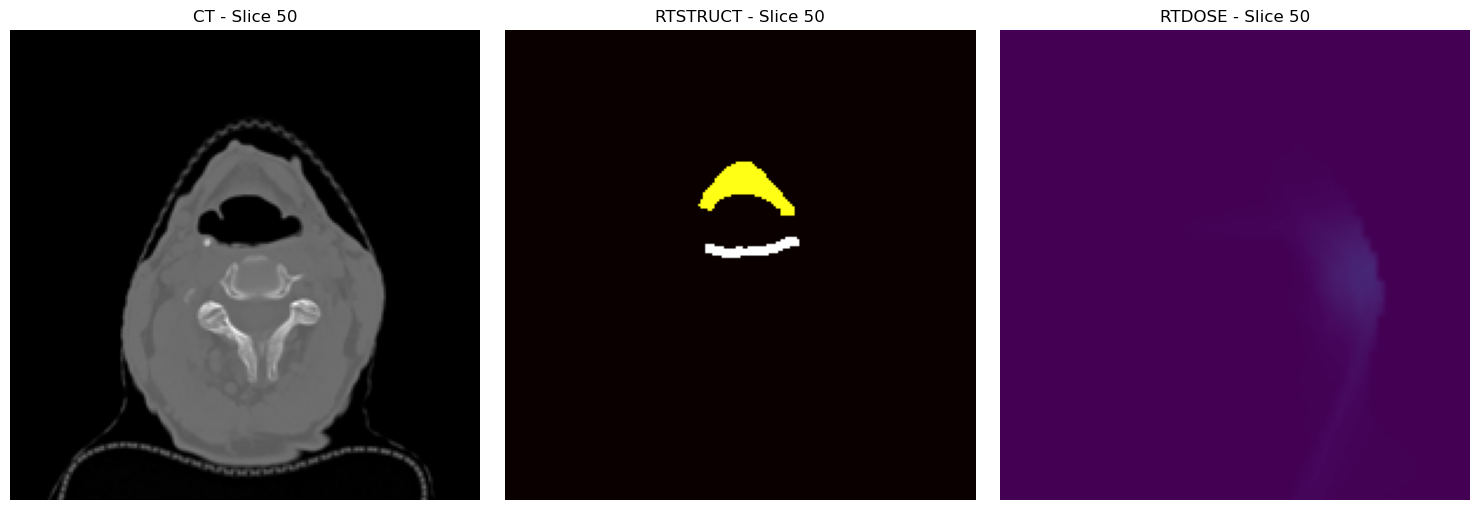

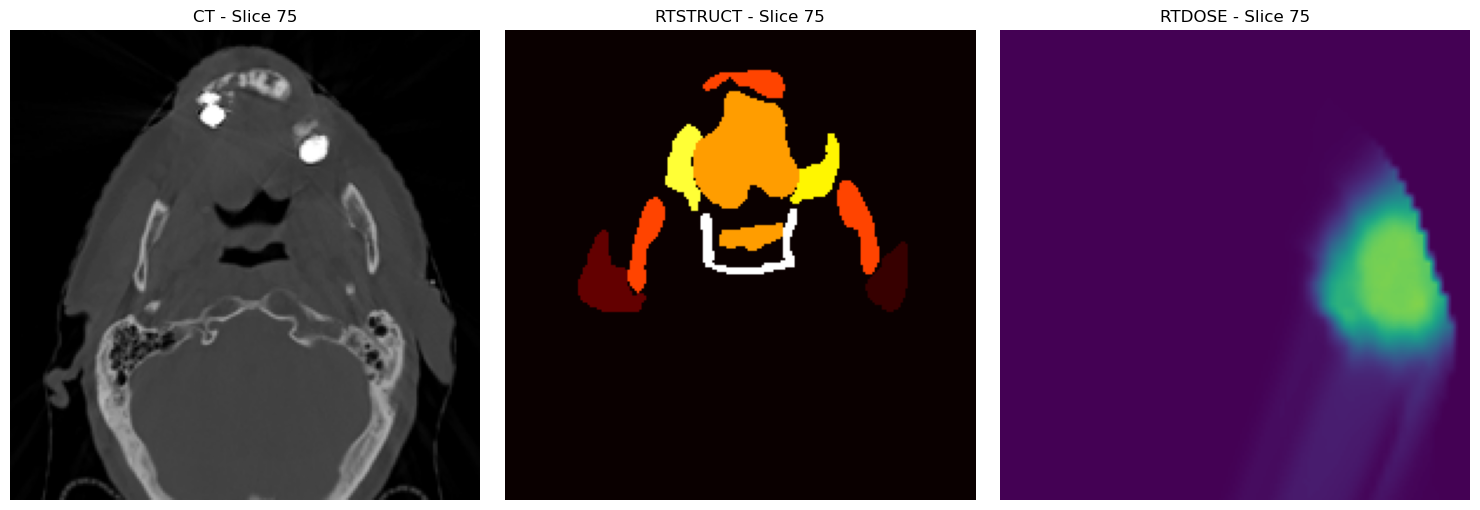

In [26]:
import matplotlib.pyplot as plt

# Select a few slices to visualize
slices = [preprocessed_CT.shape[0] // 4, preprocessed_CT.shape[0] // 2, 3 * preprocessed_CT.shape[0] // 4]

for slice_idx in slices:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Plot CT
    axes[0].imshow(preprocessed_CT[slice_idx], cmap='gray')
    axes[0].set_title(f'CT - Slice {slice_idx}')
    axes[0].axis('off')
    
    # Plot RTSTRUCT
    axes[1].imshow(preprocessed_RTSTRUCT[slice_idx], cmap='hot')
    axes[1].set_title(f'RTSTRUCT - Slice {slice_idx}')
    axes[1].axis('off')
    
    # Plot RTDOSE
    axes[2].imshow(preprocessed_RTDOSE[slice_idx], cmap='viridis', vmin=0, vmax=8400)
    axes[2].set_title(f'RTDOSE - Slice {slice_idx}')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

In [25]:
np.max(preprocessed_RTDOSE)

6860.314